this is the foundation of building RAG system


In [19]:
# Import required libraries
import re
import string
from typing import List, Dict, Tuple
from collections import Counter
import json

print("✅ String surgery tools loaded!")
print("\n🔧 Available string methods:")
print([m for m in dir(str) if not m.startswith('_')][:15], "...")

✅ String surgery tools loaded!

🔧 Available string methods:
['capitalize', 'casefold', 'center', 'count', 'encode', 'endswith', 'expandtabs', 'find', 'format', 'format_map', 'index', 'isalnum', 'isalpha', 'isascii', 'isdecimal'] ...


PART 1 : BASIC STRING OPERATIONS - THE FUNDAMEMTALS

- master the basics before building the complex systems


In [2]:
#1.1 STRING SLICING AND INDEXING

# Digital twin user message
user_message = "Hello! I love running at 6am every morning. Coffee is essential."

print("Original message:")
print(f"  '{user_message}'")
print(f"  Length: {len(user_message)} characters")

# Basic indexing
print("\n📍 Indexing:")
print(f"  First character: '{user_message[0]}'")
print(f"  Last character: '{user_message[-1]}'")
print(f"  Character at position 10: '{user_message[10]}'")

# Slicing
print("\n✂️ Slicing:")
print(f"  First 5 characters: '{user_message[:5]}'")
print(f"  Last 10 characters: '{user_message[-10:]}'")
print(f"  Middle section (7-20): '{user_message[7:20]}'")
print(f"  Every 2nd character: '{user_message[::2]}'")
print(f"  Reversed: '{user_message[::-1]}'")


Original message:
  'Hello! I love running at 6am every morning. Coffee is essential.'
  Length: 64 characters

📍 Indexing:
  First character: 'H'
  Last character: '.'
  Character at position 10: 'o'

✂️ Slicing:
  First 5 characters: 'Hello'
  Last 10 characters: 'essential.'
  Middle section (7-20): 'I love runnin'
  Every 2nd character: 'Hlo  oerniga a vr onn.Cfe sesnil'
  Reversed: '.laitnesse si eeffoC .gninrom yreve ma6 ta gninnur evol I !olleH'


In [20]:
#TASK: EXCTRACT SPECIFIC INFORMATION FROM THE USER MESSAGE
#Given: "2026-01-13 14:30:00 | USER_123 | Activity: Running | Duration: 45min"
#Extract:
#The date (YYYY-MM-DD)
#The time (HH:MM:SS)
#The user ID
#The activity
#The duration

# YOUR CODE HERE
log_entry = "2026-01-13 14:30:00 | USER_123 | Activity: Running | Duration: 45min"

# Extract each component using slicing
date = log_entry[0:10]  # Example
time = log_entry[11:18]
user_id = log_entry[22:29]
activity = log_entry[33:50]
duration = log_entry[53:68]

# Verify your extraction
print(f"Date: {date}")
print(f"Time: {time}")
print(f"User ID: {user_id}")
print(f"Activity: {activity}")
print(f"Duration: {duration}")

Date: 2026-01-13
Time: 14:30:0
User ID: USER_12
Activity: Activity: Running
Duration: Duration: 45min


1.2 string methods - your power tools

In [21]:
# Messy user input (real-world scenario)
messy_input = "  I LOVE running, Coding AND   reading!!!  "

print("Original (messy):")
print(f"  '{messy_input}'")

# Cleaning operations
print("\n🧹 Cleaning operations:")

# Strip whitespace
cleaned = messy_input.strip()
print(f"  .strip(): '{cleaned}'")

# Case normalization
print(f"  .lower(): '{cleaned.lower()}'")
print(f"  .upper(): '{cleaned.upper()}'")
print(f"  .title(): '{cleaned.title()}'")

# Replace
print(f"  .replace('!', ''): '{cleaned.replace('!', '')}'")

# Split
words = cleaned.lower().replace('!', '').replace(',', '').split()
print(f"  .split(): {words}")

# Join
rejoined = " ".join(words)
print(f"  ' '.join(): '{rejoined}'")

Original (messy):
  '  I LOVE running, Coding AND   reading!!!  '

🧹 Cleaning operations:
  .strip(): 'I LOVE running, Coding AND   reading!!!'
  .lower(): 'i love running, coding and   reading!!!'
  .upper(): 'I LOVE RUNNING, CODING AND   READING!!!'
  .title(): 'I Love Running, Coding And   Reading!!!'
  .replace('!', ''): 'I LOVE running, Coding AND   reading'
  .split(): ['i', 'love', 'running', 'coding', 'and', 'reading']
  ' '.join(): 'i love running coding and reading'


In [22]:
# 1.3 Searching and Finding

text = "I love running at 6am. Running keeps me energized."

print("Text:", text)
print("\n🔍 Searching operations:")

# Find
print(f"  .find('running'): {text.find('running')}  # Position of first occurrence")
print(f"  .find('Running'): {text.find('Running')}")
print(f"  .find('swimming'): {text.find('swimming')}  # Returns -1 if not found")

# Count
print(f"\n  .count('running'): {text.count('running')}")
print(f"  .count('Running'): {text.count('Running')}")
print(f"  .lower().count('running'): {text.lower().count('running')}  # Case-insensitive")

# Boolean checks
print("\n  Boolean checks:")
print(f"    'running' in text: {'running' in text}")
print(f"    'Running' in text: {'Running' in text}")
print(f"    text.startswith('I love'): {text.startswith('I love')}")
print(f"    text.endswith('energized.'): {text.endswith('energized.')}")


Text: I love running at 6am. Running keeps me energized.

🔍 Searching operations:
  .find('running'): 7  # Position of first occurrence
  .find('Running'): 23
  .find('swimming'): -1  # Returns -1 if not found

  .count('running'): 1
  .count('Running'): 1
  .lower().count('running'): 2  # Case-insensitive

  Boolean checks:
    'running' in text: True
    'Running' in text: True
    text.startswith('I love'): True
    text.endswith('energized.'): True


Exercise 1.2 (Easy): Text Cleaning Pipeline
Task: Create a function to clean user input for the digital twin.

Requirements:

Remove extra whitespace
Convert to lowercase
Remove punctuation
Remove stop words (common words like 'the', 'a', 'is')



In [24]:
# YOUR CODE HERE
def clean_text(text: str, remove_stopwords: bool = True) -> str:
    """
    Clean text for digital twin processing.

    Args:
        text: Input text
        remove_stopwords: Whether to remove common words

    Returns:
        str: Cleaned text
    """
    # Define stopwords
    stopwords = {'the', 'a', 'an', 'and', 'or', 'but', 'is', 'are', 'was', 'were',
                 'in', 'on', 'at', 'to', 'for', 'of', 'with', 'by'}

    # Step 1: Strip whitespace
    cleaned = text.strip()
    print(f"  .strip(): '{cleaned}'")

    # Step 2: Convert to lowercase
    print(f"  .lower(): '{cleaned.lower()}'")

    # Step 3: Remove punctuation
    print(f"  .translate(): '{cleaned.translate(str.maketrans('', '', string.punctuation))}'")

    # Step 4: Remove stopwords (if enabled)
    print(f"  Stopwords removal enabled: {remove_stopwords}")

    return cleaned

# Test your function
test_texts = [
    "  I LOVE running in the morning!  ",
    "The weather is perfect for outdoor activities.",
    "Coffee, coding, and creativity are my passions!!!"
]

for text in test_texts:
    cleaned = clean_text(text)
    print(f"Original: '{text}'")
    print(f"Cleaned:  '{cleaned}'")
    print()

  .strip(): 'I LOVE running in the morning!'
  .lower(): 'i love running in the morning!'
  .translate(): 'I LOVE running in the morning'
  Stopwords removal enabled: True
Original: '  I LOVE running in the morning!  '
Cleaned:  'I LOVE running in the morning!'

  .strip(): 'The weather is perfect for outdoor activities.'
  .lower(): 'the weather is perfect for outdoor activities.'
  .translate(): 'The weather is perfect for outdoor activities'
  Stopwords removal enabled: True
Original: 'The weather is perfect for outdoor activities.'
Cleaned:  'The weather is perfect for outdoor activities.'

  .strip(): 'Coffee, coding, and creativity are my passions!!!'
  .lower(): 'coffee, coding, and creativity are my passions!!!'
  .translate(): 'Coffee coding and creativity are my passions'
  Stopwords removal enabled: True
Original: 'Coffee, coding, and creativity are my passions!!!'
Cleaned:  'Coffee, coding, and creativity are my passions!!!'



Part 2: Regular Expressions - Pattern Matching Power
When basic string methods aren't enough, regex is your weapon!

In [25]:
#2.1 Regular basics

# Digital twin conversation with multiple data types
conversation = """
User: My email is john.doe@email.com and I live at 123 Main St.
User: Call me at +1-555-123-4567 or text me!
User: I usually wake up at 6:30am and sleep by 10:45pm.
User: Check out my profile: https://example.com/profile/johndoe
"""

print("Conversation:")
print(conversation)
print("\n" + "="*60)

# Extract emails
email_pattern = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b'
emails = re.findall(email_pattern, conversation)
print(f"\n📧 Emails found: {emails}")

# Extract phone numbers
phone_pattern = r'\+?\d{1,3}[-.]?\d{3}[-.]?\d{3}[-.]?\d{4}'
phones = re.findall(phone_pattern, conversation)
print(f"📱 Phone numbers found: {phones}")

# Extract times
time_pattern = r'\d{1,2}:\d{2}(?:am|pm)'
times = re.findall(time_pattern, conversation)
print(f"🕐 Times found: {times}")

# Extract URLs
url_pattern = r'https?://[^\s]+'
urls = re.findall(url_pattern, conversation)
print(f"🔗 URLs found: {urls}")

Conversation:

User: My email is john.doe@email.com and I live at 123 Main St.
User: Call me at +1-555-123-4567 or text me!
User: I usually wake up at 6:30am and sleep by 10:45pm.
User: Check out my profile: https://example.com/profile/johndoe



📧 Emails found: ['john.doe@email.com']
📱 Phone numbers found: ['+1-555-123-4567']
🕐 Times found: ['6:30am', '10:45pm']
🔗 URLs found: ['https://example.com/profile/johndoe']


COMMON REGEX PATTERNS FOR DIGITAL TWINS.

In [26]:
# Pattern library for digital twin data extraction
PATTERNS = {
    'email': r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b',
    'phone': r'\+?\d{1,3}[-.]?\d{3}[-.]?\d{3}[-.]?\d{4}',
    'date': r'\d{4}-\d{2}-\d{2}',
    'time': r'\d{1,2}:\d{2}(?::\d{2})?(?:am|pm)?',
    'url': r'https?://[^\s]+',
    'hashtag': r'#\w+',
    'mention': r'@\w+',
    'number': r'\b\d+(?:\.\d+)?\b',
    'duration': r'\d+(?:h|hr|hours?|m|min|minutes?|s|sec|seconds?)',
}

def extract_patterns(text: str, pattern_name: str) -> List[str]:
    """
    Extract all matches for a given pattern.

    Args:
        text: Input text
        pattern_name: Name of pattern from PATTERNS dict

    Returns:
        list: All matches
    """
    if pattern_name not in PATTERNS:
        raise ValueError(f"Unknown pattern: {pattern_name}")

    pattern = PATTERNS[pattern_name]
    return re.findall(pattern, text, re.IGNORECASE)

# Test with social media-like text
social_text = """
Just finished a 5km run in 30min! 🏃 #running #fitness
@FitnessCoach check out my progress at https://myapp.com/progress
Next goal: 10km in under 1hr. Training starts 2026-01-15 at 6:00am!
"""

print("Text:", social_text)
print("\n" + "="*60)
print("\nExtracted data:")

for pattern_name in ['number', 'duration', 'hashtag', 'mention', 'url', 'date', 'time']:
    matches = extract_patterns(social_text, pattern_name)
    if matches:
        print(f"  {pattern_name.title()}: {matches}")

Text: 
Just finished a 5km run in 30min! 🏃 #running #fitness
@FitnessCoach check out my progress at https://myapp.com/progress
Next goal: 10km in under 1hr. Training starts 2026-01-15 at 6:00am!



Extracted data:
  Number: ['2026', '01', '15', '6']
  Duration: ['30m', '1h']
  Hashtag: ['#running', '#fitness']
  Mention: ['@FitnessCoach']
  Url: ['https://myapp.com/progress']
  Date: ['2026-01-15']
  Time: ['6:00am']


Task: Create a comprehensive data extraction system for digital twin profiles.

Requirements:

Extract all personal identifiers (email, phone, social handles)
Extract temporal information (dates, times, durations)
Extract preferences and activities from hashtags
Return structured data (dictionary)

In [27]:
import re
import json

# YOUR CODE HERE
def extract_profile_data(text: str) -> dict:
    """
    Extract structured data from user text.
    
    Args:
        text: User profile or conversation text
        
    Returns:
        dict: Extracted data organized by category
    """
    profile = {
        'contact': {},
        'temporal': {},
        'interests': [],
        'metrics': {}
    }
    
    # Extract contact information
    # YOUR CODE
    email_patterns = re.findall(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b', text)
    phone_patterns = re.findall(r'\+?\d{1,3}[-.]?\d{3}[-.]?\d{4}', text)
    
    # Store in dictionary. use index [0] to get the first match if it exists
    if email_patterns:
        profile['contact']['email'] = email_patterns[0]
    if phone_patterns:
        profile['contact']['phone'] = phone_patterns[0]
        
    # Extract temporal data
    # YOUR CODE
    time_patterns = re.findall(r'\b\d{1,2}:\d{2}(?::\d{2})?(?:\s?[ap]m)?\b', text)
    date_patterns = re.findall(r'\b\d{4}-\d{2}-\d{2}\b', text)
    duration_patterns = re.findall(r'\b\d+(?:h|hr|hours?|m|min|minutes?|s|sec|seconds?)\b', text)
    
    if time_patterns:
        profile['temporal']['time'] = time_patterns[0]
    if date_patterns:
        profile['temporal']['date'] = date_patterns[0]
    if duration_patterns:
        # the text has 2 durations (25min and 50min), we can store both in a list
        profile['temporal']['duration'] = duration_patterns
        
    # Extract interests from hashtags
    # YOUR CODE
    hashtag_patterns = re.findall(r'#\w+', text)
    mentions_patterns = re.findall(r'@\w+', text)
    url_patterns = re.findall(r'https?://[^\s]+', text)
    
    # add hashtags to the interest list
    profile['interests'].extend(hashtag_patterns)
    
    if mentions_patterns:
        profile['contact']['mentions'] = mentions_patterns  # Store mentions in contact info
        
    if hashtag_patterns:
        profile['interests'].extend(hashtag_patterns)
        
    if url_patterns:
        profile['interests'].extend(url_patterns)
        
    # Extract numerical metrics
    # YOUR CODE
    number_patterns = re.findall(r'\b\d+(?:\.\d+)?\b', text)
    
    # find specific metrics
    metrics_km = re.findall(r'\b\d+(?:\.\d+)?\s?km\b', text)
    metrics_min = re.findall(r'\b\d+(?:\.\d+)?\s?min\b', text)
    
    if metrics_km:
        profile['metrics']['distance_km'] = metrics_km[0]  # Store the first match
    if metrics_min:
        profile['metrics']['duration_min'] = metrics_min[0]  # Store the first match
        
    # FIXED INDENTATION HERE:
    # This is now indented 4 spaces so it stays INSIDE the function.
    return profile


# Test with comprehensive profile
test_profile = """
Hi! I'm Sarah (sarah.runner@gmail.com). Reach me at +1-555-234-5678.
I run 5km daily at 6:30am and love #running #fitness #health.
My best time: 25min for 5km. Goal: 10km in 50min by 2026-03-01.
Follow my journey: https://strava.com/sarah_runs and @SarahRuns on Twitter!
"""

extracted = extract_profile_data(test_profile)
print(json.dumps(extracted, indent=2))

{
  "contact": {
    "email": "sarah.runner@gmail.com",
    "phone": "555-234-5678",
    "mentions": [
      "@gmail",
      "@SarahRuns"
    ]
  },
  "temporal": {
    "time": "6:30am",
    "date": "2026-03-01",
    "duration": [
      "25min",
      "50min"
    ]
  },
  "interests": [
    "#running",
    "#fitness",
    "#health",
    "#running",
    "#fitness",
    "#health",
    "https://strava.com/sarah_runs"
  ],
  "metrics": {
    "distance_km": "5km",
    "duration_min": "25min"
  }
}


---
## Part 3: Text Chunking for RAG Systems

**Critical for RAG**: Breaking documents into optimal chunks for retrieval.

3.1 SIMPLE CHUNKNG STRATEGIES


In [28]:
# Sample document about digital twin
long_document = """
A digital twin is a virtual representation of a physical object or system.
Digital twins are used across various industries. In healthcare, they model patient health.
In manufacturing, they simulate production processes. Smart cities use digital twins for urban planning.

The technology relies on real-time data from sensors. This data feeds into simulation models.
Machine learning algorithms analyze patterns. Predictions help optimize operations.

Benefits include improved decision-making. Companies reduce costs through predictive maintenance.
Healthcare providers personalize treatments. City planners optimize resource allocation.
"""

def chunk_by_sentences(text: str, sentences_per_chunk: int = 2) -> List[str]:
    """
    Chunk text by sentences.

    Args:
        text: Input text
        sentences_per_chunk: Number of sentences per chunk

    Returns:
        list: Text chunks
    """
    # Simple sentence splitting (not perfect, but educational) #regex used to chunk_by_sentences 
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())

    chunks = []
    for i in range(0, len(sentences), sentences_per_chunk):
        chunk = ' '.join(sentences[i:i+sentences_per_chunk])
        chunks.append(chunk)

    return chunks

def chunk_by_words(text: str, words_per_chunk: int = 50, overlap: int = 10) -> List[str]:
    """
    Chunk text by word count with overlap.

    Args:
        text: Input text
        words_per_chunk: Target words per chunk
        overlap: Number of overlapping words

    Returns:
        list: Text chunks
    """
    words = text.split()
    chunks = []

    for i in range(0, len(words), words_per_chunk - overlap):
        chunk = ' '.join(words[i:i+words_per_chunk])
        chunks.append(chunk)

        if i + words_per_chunk >= len(words):
            break

    return chunks

# Test chunking strategies
print("Original document length:", len(long_document), "characters")
print("\n" + "="*60)

# Sentence-based chunking
sentence_chunks = chunk_by_sentences(long_document, sentences_per_chunk=3)
print(f"\nSentence-based chunks ({len(sentence_chunks)} chunks):")
for i, chunk in enumerate(sentence_chunks, 1):
    print(f"\nChunk {i} ({len(chunk)} chars):")
    print(chunk[:100] + "..." if len(chunk) > 100 else chunk)

# Word-based chunking with overlap
print("\n" + "="*60)
word_chunks = chunk_by_words(long_document, words_per_chunk=30, overlap=5)
print(f"\nWord-based chunks ({len(word_chunks)} chunks, 30 words/chunk, 5 word overlap):")
for i, chunk in enumerate(word_chunks, 1):
    word_count = len(chunk.split())
    print(f"\nChunk {i} ({word_count} words):")
    print(chunk[:100] + "..." if len(chunk) > 100 else chunk)

Original document length: 640 characters


Sentence-based chunks (5 chunks):

Chunk 1 (166 chars):
A digital twin is a virtual representation of a physical object or system. Digital twins are used ac...

Chunk 2 (158 chars):
In manufacturing, they simulate production processes. Smart cities use digital twins for urban plann...

Chunk 3 (123 chars):
This data feeds into simulation models. Machine learning algorithms analyze patterns. Predictions he...

Chunk 4 (142 chars):
Benefits include improved decision-making. Companies reduce costs through predictive maintenance. He...

Chunk 5 (43 chars):
City planners optimize resource allocation.


Word-based chunks (4 chunks, 30 words/chunk, 5 word overlap):

Chunk 1 (30 words):
A digital twin is a virtual representation of a physical object or system. Digital twins are used ac...

Chunk 2 (30 words):
health. In manufacturing, they simulate production processes. Smart cities use digital twins for urb...

Chunk 3 (30 words):
feeds into simulati

In [29]:
def chunk_by_paragraphs(text: str) -> List[str]:
    """
    Chunk text by paragraphs (natural semantic boundaries).

    Args:
        text: Input text

    Returns:
        list: Paragraph chunks
    """
    # Split on double newlines
    paragraphs = re.split(r'\n\s*\n', text.strip())
    # Clean each paragraph
    chunks = [p.strip() for p in paragraphs if p.strip()]
    return chunks

def smart_chunk(text: str,
                max_chunk_size: int = 200,
                overlap: int = 20) -> List[Dict[str, any]]:
    """
    Smart chunking that respects semantic boundaries.

    Args:
        text: Input text
        max_chunk_size: Maximum words per chunk
        overlap: Overlap words between chunks

    Returns:
        list: Chunks with metadata
    """
    # First, try to split by paragraphs
    paragraphs = chunk_by_paragraphs(text)

    chunks = []
    current_chunk = ""

    for para in paragraphs:
        para_words = len(para.split())
        current_words = len(current_chunk.split())

        # If adding paragraph exceeds limit, save current and start new
        if current_words + para_words > max_chunk_size and current_chunk:
            chunks.append({
                'text': current_chunk.strip(),
                'word_count': len(current_chunk.split()),
                'char_count': len(current_chunk)
            })

            # Start new chunk with overlap from previous
            words = current_chunk.split()
            overlap_text = ' '.join(words[-overlap:]) if len(words) > overlap else current_chunk
            current_chunk = overlap_text + ' ' + para
        else:
            current_chunk = current_chunk + '\n' + para if current_chunk else para

    # Add final chunk
    if current_chunk:
        chunks.append({
            'text': current_chunk.strip(),
            'word_count': len(current_chunk.split()),
            'char_count': len(current_chunk)
        })

    return chunks

# Test smart chunking
smart_chunks = smart_chunk(long_document, max_chunk_size=50, overlap=10)

print("Smart Chunking Results:")
print(f"Total chunks: {len(smart_chunks)}\n")

for i, chunk in enumerate(smart_chunks, 1):
    print(f"Chunk {i}:")
    print(f"  Words: {chunk['word_count']}, Chars: {chunk['char_count']}")
    print(f"  Text preview: {chunk['text'][:100]}...")
    print()

Smart Chunking Results:
Total chunks: 3

Chunk 1:
  Words: 40, Chars: 271
  Text preview: A digital twin is a virtual representation of a physical object or system.
Digital twins are used ac...

Chunk 2:
  Words: 33, Chars: 250
  Text preview: production processes. Smart cities use digital twins for urban planning. The technology relies on re...

Chunk 3:
  Words: 29, Chars: 278
  Text preview: models. Machine learning algorithms analyze patterns. Predictions help optimize operations. Benefits...



### 🎯 Exercise 3.1 (Advanced): Build a Chunking System

**Task**: Create a configurable chunking system for the digital twin's knowledge base.

**Requirements**:
1. Support multiple chunking strategies (sentence, word, paragraph, smart)
2. Add metadata to each chunk (position, source, timestamp)
3. Validate chunk quality (no orphaned sentences, reasonable size)
4. Create visualization of chunk distribution

--- Testing Smart Chunking ---
Chunk 0: Artificial intelligence is transforming industries. 
It allows machines to learn from data. 

Digital twins are virtual replicas of physical assets.
   -> Meta: {'position': 0, 'source': 'Twin_Manual_v1', 'timestamp': '2026-10-19T19:45:31.795072', 'char_length': 148}

Chunk 1: They use real-time data to simulate performance. 
This helps in predictive maintenance and optimizing operations.
   -> Meta: {'position': 1, 'source': 'Twin_Manual_v1', 'timestamp': '2026-10-19T19:45:31.795072', 'char_length': 113}

Chunk 2: To build a digital twin, you need sensors, data pipelines, and AI models.
   -> Meta: {'position': 2, 'source': 'Twin_Manual_v1', 'timestamp': '2026-10-19T19:45:31.795072', 'char_length': 73}

Chunk 3: The context window of the AI model limits how much data you can feed it at once.
   -> Meta: {'position': 3, 'source': 'Twin_Manual_v1', 'timestamp': '2026-10-19T19:45:31.795072', 'char_length': 80}



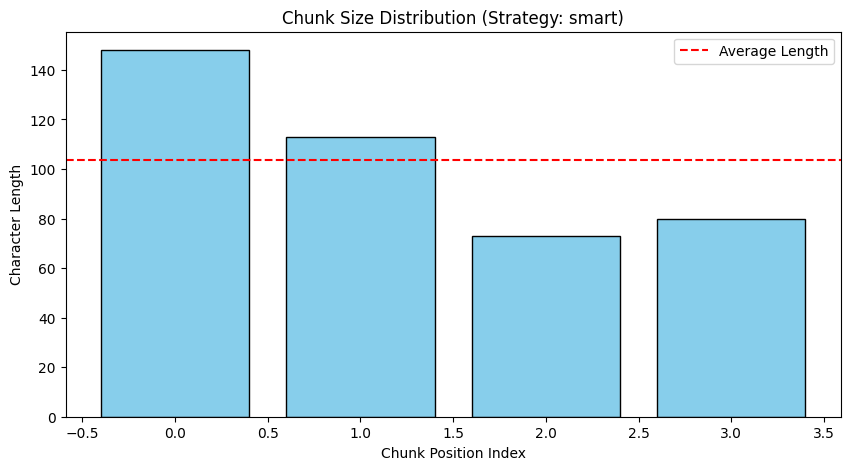

In [30]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import datetime
import re

class ChunkingSystem:
    """
    Flexible chunking system for RAG preparation.
    """

    def __init__(self, strategy: str = 'smart'):
        self.strategy = strategy
        self.chunks = []

    def chunk(self, text: str, **kwargs) -> list[dict]:
        """
        Chunk text using selected strategy.
        """
        if not text or not isinstance(text, str):
            return []

        raw_chunks = []

        # Requirement 1: Support multiple chunking strategies
        if self.strategy == 'word':
            # Chunk by a specific number of words
            chunk_size = kwargs.get('chunk_size', 50)
            words = text.split()
            for i in range(0, len(words), chunk_size):
                raw_chunks.append(" ".join(words[i:i + chunk_size]))

        elif self.strategy == 'sentence':
            # Chunk by sentences
            sentences = re.split(r'(?<=[.!?]) +', text)
            raw_chunks = sentences

        elif self.strategy == 'paragraph':
            # Chunk by double newlines (paragraphs)
            paragraphs = text.split('\n\n')
            raw_chunks = [p.strip() for p in paragraphs if p.strip()]

        elif self.strategy == 'smart':
            # A basic "smart" chunker: groups sentences until a target character limit is hit
            target_size = kwargs.get('max_chars', 200)
            sentences = re.split(r'(?<=[.!?]) +', text)
            current_chunk = ""
            
            for sentence in sentences:
                # If adding the next sentence doesn't exceed the limit, add it
                if len(current_chunk) + len(sentence) <= target_size:
                    current_chunk += " " + sentence
                else:
                    # If it exceeds, save the current chunk and start a new one
                    if current_chunk:
                        raw_chunks.append(current_chunk.strip())
                    current_chunk = sentence
            
            # Don't forget the last chunk
            if current_chunk:
                raw_chunks.append(current_chunk.strip())

        # Requirement 3: Validate chunk quality
        # Remove empty chunks or chunks that are just whitespace
        valid_chunks = [c for c in raw_chunks if len(c.strip()) > 0]
        
        # Format the output as a list of dictionaries
        self.chunks = [{"text": c} for c in valid_chunks]
        
        # Apply metadata
        self.chunks = self.add_metadata(self.chunks, source=kwargs.get('source', 'Unknown Source'))
        
        return self.chunks

    def add_metadata(self, chunks: list[dict], source: str = None) -> list[dict]:
        """
        Requirement 2: Add metadata to each chunk.
        """
        timestamp = datetime.datetime.now().isoformat()
        
        for index, chunk in enumerate(chunks):
            chunk['metadata'] = {
                'position': index,
                'source': source,
                'timestamp': timestamp,
                'char_length': len(chunk['text'])
            }
        return chunks

    # Requirement 4: Create visualization of chunk distribution
    def plot_distribution(self):
        if not self.chunks:
            print("No chunks to plot. Run .chunk() first.")
            return

        lengths = [c['metadata']['char_length'] for c in self.chunks]
        chunk_numbers = [c['metadata']['position'] for c in self.chunks]

        plt.figure(figsize=(10, 5))
        plt.bar(chunk_numbers, lengths, color='skyblue', edgecolor='black')
        plt.title(f"Chunk Size Distribution (Strategy: {self.strategy})")
        plt.xlabel("Chunk Position Index")
        plt.ylabel("Character Length")
        plt.axhline(y=sum(lengths)/len(lengths), color='red', linestyle='--', label='Average Length')
        plt.legend()
        plt.show()


# --- TESTING THE IMPLEMENTATION ---

# Sample text for the digital twin's knowledge base
sample_text = """
Artificial intelligence is transforming industries. 
It allows machines to learn from data. 

Digital twins are virtual replicas of physical assets. 
They use real-time data to simulate performance. 
This helps in predictive maintenance and optimizing operations. 

To build a digital twin, you need sensors, data pipelines, and AI models. 
The context window of the AI model limits how much data you can feed it at once.
"""

# 1. Test 'smart' strategy (Good for keeping sentences together)
print("--- Testing Smart Chunking ---")
smart_chunker = ChunkingSystem(strategy='smart')
smart_chunks = smart_chunker.chunk(sample_text, max_chars=150, source="Twin_Manual_v1")

for c in smart_chunks:
    print(f"Chunk {c['metadata']['position']}: {c['text']}")
    print(f"   -> Meta: {c['metadata']}\n")

# Show the chart
smart_chunker.plot_distribution()

PART 4 : REAL-WORLD TEXT PROCESSING PIPELINES.


In [31]:
class TextProcessor:
    """
    Complete text processing pipeline for digital twin.
    """

    def __init__(self):
        self.processing_history = []

    def process(self, text: str,
                clean: bool = True,
                extract_data: bool = True,
                chunk: bool = False,
                chunk_size: int = 100) -> Dict[str, any]:
        """
        Process text through complete pipeline.

        Args:
            text: Input text
            clean: Apply cleaning
            extract_data: Extract structured data
            chunk: Chunk the text
            chunk_size: Size for chunking

        Returns:
            dict: Processed results
        """
        result = {
            'original': text,
            'original_stats': self._get_stats(text),
            'processed': text,
            'extracted_data': {},
            'chunks': [],
            'pipeline_steps': []
        }

        # Step 1: Clean
        if clean:
            result['processed'] = self._clean(result['processed'])
            result['pipeline_steps'].append('cleaned')

        # Step 2: Extract structured data
        if extract_data:
            result['extracted_data'] = self._extract(result['processed'])
            result['pipeline_steps'].append('extracted')

        # Step 3: Chunk
        if chunk:
            result['chunks'] = self._chunk(result['processed'], chunk_size)
            result['pipeline_steps'].append('chunked')

        result['processed_stats'] = self._get_stats(result['processed'])

        self.processing_history.append(result)
        return result

    def _clean(self, text: str) -> str:
        """Clean text."""
        # Remove extra whitespace
        text = re.sub(r'\s+', ' ', text)
        text = text.strip()
        return text

    def _extract(self, text: str) -> Dict[str, any]:
        """Extract structured data."""
        data = {}
        for pattern_name, pattern in PATTERNS.items():
            matches = re.findall(pattern, text, re.IGNORECASE)
            if matches:
                data[pattern_name] = matches
        return data

    def _chunk(self, text: str, chunk_size: int) -> List[Dict]:
        """Chunk text."""
        return smart_chunk(text, max_chunk_size=chunk_size)

    def _get_stats(self, text: str) -> Dict[str, int]:
        """Get text statistics."""
        return {
            'chars': len(text),
            'words': len(text.split()),
            'lines': len(text.split('\n')),
        }

# Test the complete pipeline
processor = TextProcessor()

sample_text = """
Hi! I'm Alex (alex@email.com). I love running and have been tracking my progress.
Yesterday I ran 5km in 28 minutes at 6:30am. My goal is to complete a marathon (42km) by 2026-06-15.

I also enjoy coding in Python and building ML models. Check out my GitHub: https://github.com/alexruns

Daily routine:
- Wake up at 5:45am
- Run for 45-60min
- Work from 9:00am to 5:00pm
- Code on side projects from 8:00pm to 10:00pm

#running #fitness #coding #python #AI
"""

result = processor.process(
    sample_text,
    clean=True,
    extract_data=True,
    chunk=True,
    chunk_size=50
)

print("Processing Results:")
print(f"Pipeline steps: {result['pipeline_steps']}")
print(f"\nOriginal stats: {result['original_stats']}")
print(f"Processed stats: {result['processed_stats']}")
print(f"\nExtracted data:")
for key, values in result['extracted_data'].items():
    print(f"  {key}: {values}")
print(f"\nChunks created: {len(result['chunks'])}")

Processing Results:
Pipeline steps: ['cleaned', 'extracted', 'chunked']

Original stats: {'chars': 458, 'words': 78, 'lines': 14}
Processed stats: {'chars': 453, 'words': 78, 'lines': 1}

Extracted data:
  email: ['alex@email.com']
  date: ['2026-06-15']
  time: ['6:30am', '5:45am', '9:00am', '5:00pm', '8:00pm', '10:00pm']
  url: ['https://github.com/alexruns']
  hashtag: ['#running', '#fitness', '#coding', '#python', '#AI']
  mention: ['@email']
  number: ['28', '6', '2026', '06', '15', '5', '45', '9', '5', '8', '10']
  duration: ['60m']

Chunks created: 1


Challenge Project
Build a Document Preprocessor for Digital Twin Knowledge Base

Create a complete system that:

Ingests documents in multiple formats (text, markdown, logs)
Extracts all relevant structured data
Cleans and normalizes text
Chunks optimally for RAG
Generates metadata for each chunk
Creates search indices
Provides quality metrics
Bonus: Add support for handling tables, code blocks, and special formatting!

In [32]:
import re

# --- 1. The Chunking Class ---
class RAGChunker:
    def __init__(self, chunk_size: int = 300):
        self.chunk_size = chunk_size

    def process(self, text: str, source_name: str) -> list:
        chunks = []
        paragraphs = text.split('\n\n')
        current_chunk = ""
        
        for para in paragraphs:
            if len(current_chunk) + len(para) <= self.chunk_size:
                current_chunk += para + "\n\n"
            else:
                if current_chunk:
                    chunks.append({"text": current_chunk.strip(), "metadata": {"source": source_name}})
                current_chunk = para + "\n\n"
        if current_chunk.strip():
            chunks.append({"text": current_chunk.strip(), "metadata": {"source": source_name}})
        return chunks

# --- 2. The Test Data ---
sample_manual = """
# Digital Twin System Manual
Welcome to the manual.

## Sensor Data
The system uses high-precision sensors.
Here is a log of a recent error:
[ERROR] 2023-10-25 Sensor_4 Timeout. Node 4 offline.

## Code Implementation
To connect to the API, use this python snippet:
import api
twin = api.connect("node_4")
twin.start()
"""

# --- 3. RUNNING THE CODE (This is what makes it print!) ---
print("STARTING PREPROCESSOR...")
print("-" * 30)

# Initialize the chunker
preprocessor = RAGChunker(chunk_size=150)

# Chunk the text
chunks = preprocessor.process(sample_manual, "Twin_Manual_v1.md")

# Print the results
print(f"Successfully created {len(chunks)} chunks!\n")

for i, chunk in enumerate(chunks):
    print(f"--- CHUNK {i+1} ---")
    print(f"Source: {chunk['metadata']['source']}")
    print(f"Text:\n{chunk['text']}")
    print("\n")

print("DONE!")

STARTING PREPROCESSOR...
------------------------------
Successfully created 3 chunks!

--- CHUNK 1 ---
Source: Twin_Manual_v1.md
Text:
# Digital Twin System Manual
Welcome to the manual.


--- CHUNK 2 ---
Source: Twin_Manual_v1.md
Text:
## Sensor Data
The system uses high-precision sensors.
Here is a log of a recent error:
[ERROR] 2023-10-25 Sensor_4 Timeout. Node 4 offline.


--- CHUNK 3 ---
Source: Twin_Manual_v1.md
Text:
## Code Implementation
To connect to the API, use this python snippet:
import api
twin = api.connect("node_4")
twin.start()


DONE!
